# MindMiner · Transformer classification
### Understand the idea, follow the code, then interpret the evidence

This notebook fine-tunes **BERT, RoBERTa, and DistilBERT** to predict
stressors, relationships, emotions, and responses from a post. It starts
with a fictional example so that each technical step has a clear purpose.

**Reading route:** the task → text as numbers → contextual representations
→ tag scores → learning → development evaluation → final test.

Only `text_clean` is a prediction input. The supplied helper declares
**31 tags** across four families. TBe/PBu annotations stay as metadata.
The first examples below are invented for teaching; they are not results.

**Before the full run:** install PyTorch and `requirements.txt`, put your
dataset in `data/processed/`, and review the settings. The original
settings require **18 training fits with 10 epochs each**. This package
has not been trained or evaluated on your dataset.

## 1. What are we trying to predict?

Imagine a post: **“I argued with my family and feel anxious. Can someone
offer advice?”** It may contain several kinds of information together.

| Question | Label family | Example tag |
| --- | --- | --- |
| What difficulty is mentioned? | Stressors | `family conflict` |
| Who is involved? | Relationships | `family` |
| What feeling is expressed? | Emotions | `anxiety` |
| What response is described? | Responses | `advice seeking` |

These illustrate the task; real annotations follow the codebook. A label
is one possible answer. Because several answers can be present together,
this is **multilabel classification**. We make a separate yes/no decision
for each of the 31 tags.

**A target vector** records the expected answers using 1 for present and
0 for absent. Run the small example below to see a slice of that vector.

In [ ]:
# Teaching example only: five selected tags out of the full vocabulary.
toy_label_order = ['family conflict', 'family', 'anxiety', 'advice seeking', 'grief']
toy_present_tags = {'family conflict', 'family', 'anxiety', 'advice seeking'}
toy_target = [int(tag in toy_present_tags) for tag in toy_label_order]
for tag, target in zip(toy_label_order, toy_target):
    print(f'{tag:18s} -> {target}')
print('Target vector:', toy_target)

## 2. What does BERT do with the text?

A computer model operates on numbers. A **tokenizer** first divides a post
into tokens, which can be words, word pieces, or punctuation, then looks
up their vocabulary IDs. An ID is an address, not a measure of meaning.

Learned **embeddings** turn those IDs into vectors. Position information
represents token order. **Self-attention** combines information from
tokens in the same post, helping representations reflect context. For
example, “happy” appears in both “happy” and “not happy”; the surrounding
words matter. Attention heads do not have guaranteed human-readable roles.

Encoder blocks apply attention and feed-forward transformations with
normalization and residual connections. A **classification head** then
turns encoder output into 31 scores. Fine-tuning adjusts both the encoder
and the head to learn from this dataset's reference annotations.

## Follow one fictional post

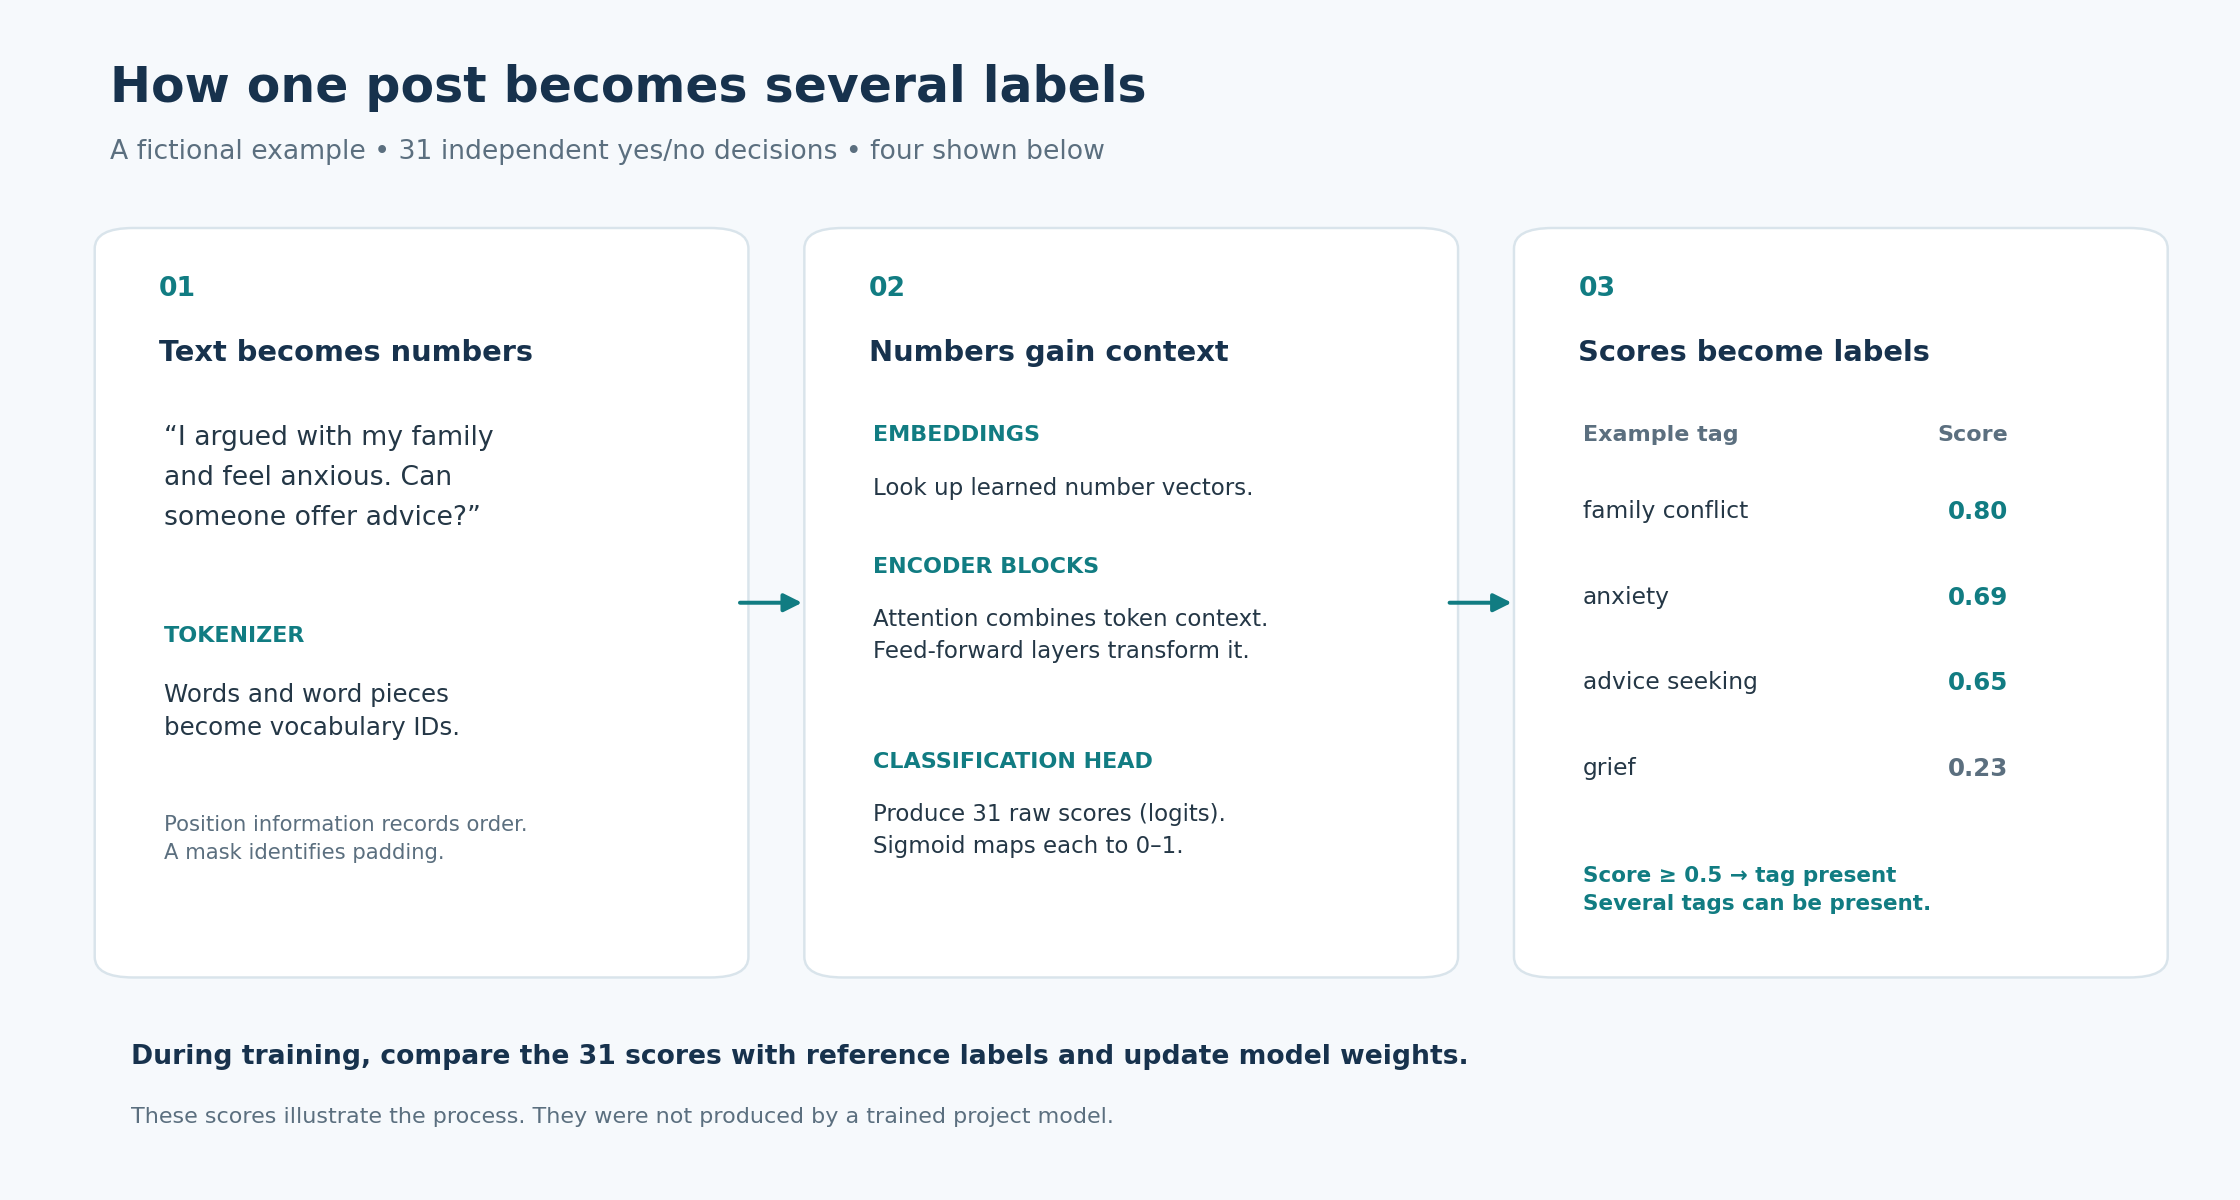

Four of the 31 outputs are shown. The numbers are illustrative. The full model makes all 31 decisions independently.

### How does attention combine information?

Learned projections create a **query**, **key**, and **value** vector for
each token. For one query token, compare its query with other tokens'
keys. Scaled dot products produce compatibility scores. A softmax over
token positions converts those scores into weights. The attention output
is a weighted sum of the value vectors.

The toy calculation below assumes two scores, 2 and 1, and two value
vectors. It demonstrates the arithmetic without loading a model. Multiple
heads repeat related calculations in different learned vector spaces.

Softmax **inside attention** distributes weight across token positions.
Sigmoid **at the classifier output** makes independent tag decisions.
Those are different jobs, so both can appear in the same model.

In [ ]:
import math

toy_attention_scores = [2.0, 1.0]  # Invented query–key compatibility scores.
toy_values = [[2.0, 0.0], [0.0, 2.0]]
# Subtracting the maximum makes softmax numerically stable.
exp_scores = [math.exp(s - max(toy_attention_scores)) for s in toy_attention_scores]
attention_weights = [s / sum(exp_scores) for s in exp_scores]
combined_vector = [
    sum(weight * vector[d] for weight, vector in zip(attention_weights, toy_values))
    for d in range(2)
]
print('Attention weights:', [round(w, 3) for w in attention_weights])
print('Combined vector:', [round(x, 3) for x in combined_vector])

## 3. How do raw scores become yes/no answers?

A **logit** is a raw score that can be negative or positive. **Sigmoid**
converts each logit separately into a number between 0 and 1. This
notebook predicts a tag when its sigmoid score is at least **0.5**.

A positive logit gives a score above 0.5; a negative logit gives a score
below 0.5. Several labels can pass the threshold together. The scores
do not need to sum to 1. A softmax over these 31 tags would impose a
competition that does not match this independent-label setup.

The next example uses made-up logits so you can inspect this operation
without loading or training a model. Scores are not guaranteed to be
calibrated probabilities of correctness.

In [ ]:
import math

toy_logits = {'anxiety': 1.4, 'advice seeking': 0.8, 'grief': -1.2}
for tag, logit in toy_logits.items():
    score = 1 / (1 + math.exp(-logit))
    predicted = int(score >= 0.5)
    print(f'{tag:18s} logit={logit:5.1f}  score={score:.3f}  predicted={predicted}')

## 4. Which three models are compared?

| Model | Idea | Identifier |
| --- | --- | --- |
| BERT | A pretrained encoder using context from both directions | `google-bert/bert-base-uncased` |
| RoBERTa | A BERT-style encoder with a revised pretraining recipe | `FacebookAI/roberta-base` |
| DistilBERT | A smaller encoder trained using knowledge distillation | `distilbert/distilbert-base-uncased` |

Their tokenizers and pretrained representations differ. We use the same
task, preparation, folds, and metric definitions for comparison. Which
performs best on these data is an experimental question.

## 5. Connect the notebook to the shared toolbox

The next cell finds the complete repository and imports the shared 31-tag
codebook. Keep all modules in `src/`. Set `PROJECT_ROOT` when using another
working directory or a Kaggle/Colab mount. The selected root and label count
are printed so you can check which code is being used.


In [ ]:
from pathlib import Path
import os
import sys

# Leave None when running from the repository root or notebooks/.
# On Kaggle/Colab, set this to the extracted repository directory when needed.
PROJECT_ROOT = os.environ.get("MINDMINER_PROJECT_ROOT")
if PROJECT_ROOT:
    REPO_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    REPO_ROOT = next((p for p in [here, *here.parents]
                      if (p / "src/mindminer_codebook.py").is_file()), None)
if REPO_ROOT is None or not (REPO_ROOT / "src/mindminer_codebook.py").is_file():
    raise FileNotFoundError("Extract the complete MindMiner repository and set PROJECT_ROOT to its folder.")
sys.path.insert(0, str(REPO_ROOT / "src"))
RUN_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else REPO_ROOT
from mindminer_codebook import CODEBOOK_VERSION, CODEBOOK_SHA256, CODEBOOK, FIELDS, TAGS, LABELS
print("Project root:", REPO_ROOT)
print("Codebook:", CODEBOOK_VERSION, "| tags:", len(LABELS))

### Packages and notebook kernels

A Python package supplies code written for a particular job. NumPy
handles arrays, pandas handles tables, PyTorch handles the neural
network, and Transformers loads the pretrained model and tokenizer.

Use `python -m pip install -r requirements.txt` from the project root
after installing PyTorch for your hardware. In Kaggle, uncomment and
run the optional line below if packages are missing. The kernel must
already have PyTorch. Restart it if an installation asks you to do so.

In [ ]:
# Optional for a notebook kernel without these packages; uncomment to run.
# %pip install -q numpy pandas scikit-learn iterative-stratification==0.1.9 matplotlib transformers safetensors openpyxl

## 6. Set up the experiment before viewing results

A **hyperparameter** is a choice made before training, such as the
learning rate or epoch count. The supplied code fixes these choices;
it does not search for settings using test performance.

| Setting | Meaning |
| --- | --- |
| `N_SPLITS=5` | Rotate five development training/validation folds |
| `MAX_LENGTH=512` | At most 512 tokens per post, including special tokens |
| `BATCH_SIZE=4` | Up to four posts in one mini-batch |
| `GRAD_ACCUMULATION=4` | Combine four mini-batches before an optimizer update |
| `EPOCHS=10` | Ten passes through the training partition for each fit |
| `LEARNING_RATE=2e-5` | The scale used for model-weight updates |
| `SAVE_FINAL_MODELS=False` | Keep model saving optional |

CUDA uses an available compatible NVIDIA GPU; otherwise this code uses
CPU. Both the model and the tensors must be on the selected device.
GPU acceleration does not replace the need for a correct evaluation.

**Check `DATA_FILE` below.** It defaults to the local CSV, or another path you set explicitly. Set the path explicitly if
your dataset is elsewhere or has a different extension.

In [ ]:
from pathlib import Path
import os
import gc
import math
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

import importlib
import mindminer_utils
importlib.reload(mindminer_utils)

from mindminer_utils import (
    LABELS, find_data_file, load_data, encode_labels, make_folds,
    save_fold_plan, metrics, write_evaluation, summarize_cv, save_json, save_classification_reports,
)

# Set DATA_FILE to your actual file; changing its extension does not convert it.
LOCAL_DATA_FILE = REPO_ROOT / "data/processed/easy_dataset.csv"
DEFAULT_DATA_FILE = LOCAL_DATA_FILE
DATA_FILE = os.environ.get("MINDMINER_DATA_FILE", str(DEFAULT_DATA_FILE))
OUTPUT = RUN_ROOT / "results/transformers"
MODEL_NAMES = {
    "BERT": "google-bert/bert-base-uncased",
    "RoBERTa": "FacebookAI/roberta-base",
    "DistilBERT": "distilbert/distilbert-base-uncased",
}
SEED = 42
N_SPLITS = 5
MAX_LENGTH = 512      # Maximum total tokens per post, including special tokens.
BATCH_SIZE = 4        # Lower to 2 or 1 if CUDA runs out of memory.
GRAD_ACCUMULATION = 4 # Effective batch size = 4 × 4 = 16 on one GPU.
EPOCHS = 10           # Fixed in advance; no checkpoint selection on outer validation/test.
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
USE_CLASS_WEIGHTS = True
SAVE_FINAL_MODELS = False

# CUDA is used for both the model and every input/label tensor when available.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.is_bf16_supported() else torch.float16
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Total VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
    print("Mixed precision:", AMP_DTYPE)
else:
    print("CUDA is unavailable in this Python environment; training will use CPU.")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def show_gpu_usage():
    if DEVICE.type == "cuda":
        print(f"PyTorch VRAM allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GiB; "
              f"peak: {torch.cuda.max_memory_allocated()/1024**3:.2f} GiB")
        try:
            status = subprocess.run(
                ["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used,memory.total", "--format=csv,noheader"],
                capture_output=True, text=True, timeout=5,
            )
            if status.returncode == 0:
                print(status.stdout.strip())
        except (OSError, subprocess.TimeoutExpired):
            pass

print("Data file:", DATA_FILE)
print("Planned fits:", len(MODEL_NAMES) * (N_SPLITS + 1))


## 7. Prepare the data and reference labels

`load_data()` reads the table by column names, validates the values,
removes empty text, and removes consistent duplicate-text copies.
It rejects conflicting annotations and repeated post IDs. For consistent
text duplicates it prioritizes the test copy, then val, then train.
This checks normalized exact text, not every possible paraphrase.

Only the text is a model feature. The four tag columns become 31 binary
targets: **10 stressors + 7 relationships + 8 emotions + 6 responses**.
TBe (`belong`), PBu (`burden`), and `group` remain metadata. Review flags,
if present, filter rows before those optional columns are dropped.

**Important meaning of a blank:** a blank tag cell means no tags in that
family in this loader. If it means “not yet annotated” in your export,
resolve that distinction first.

Original train + val becomes development. Test stays separate. The
printed counts come from the supplied file at run time. No dataset
counts are assumed in this notebook.

## See the five-fold plan

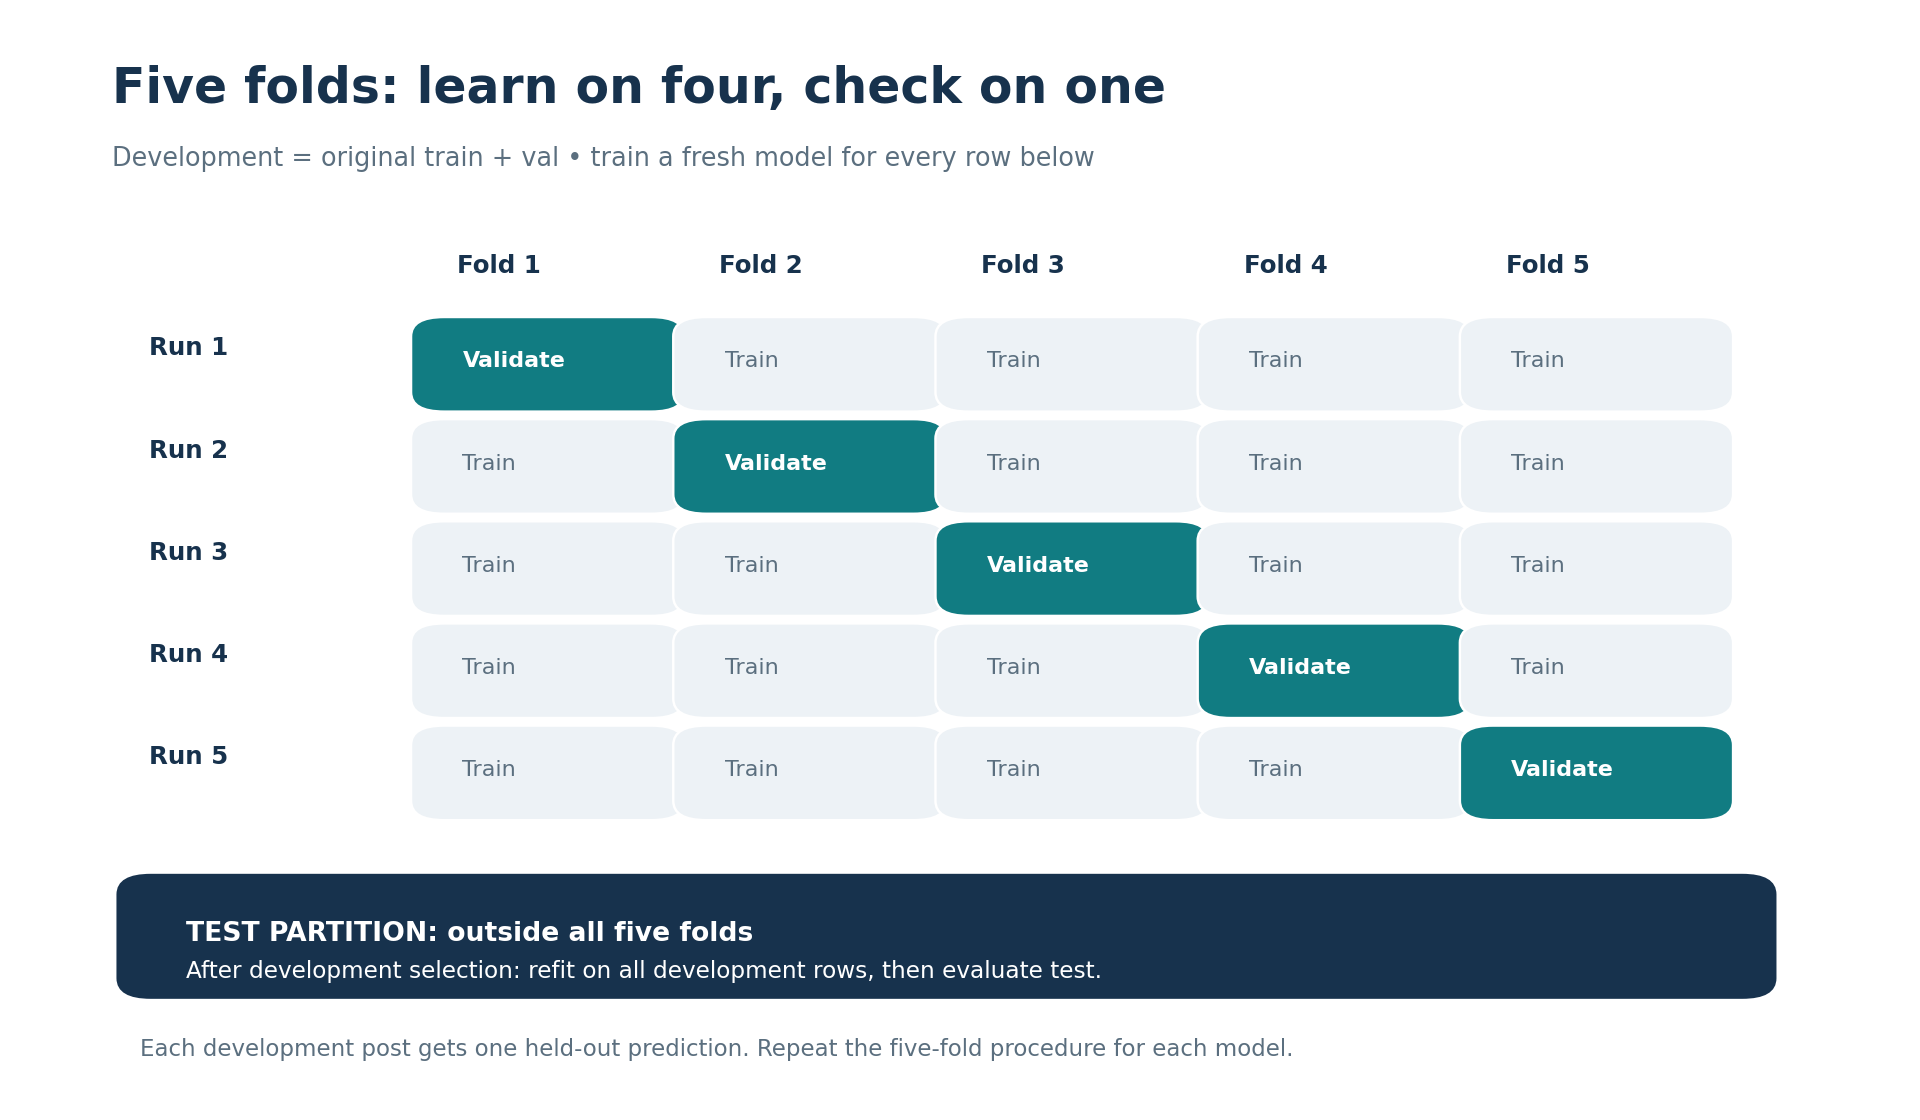

Multilabel stratification tries to balance the 31 tags and TBe/PBu groups across the development folds. Group metadata helps assign folds but never enters the prediction features.

In [ ]:
data_path = find_data_file(DATA_FILE)
all_posts, dev, test, audit = load_data(data_path)
y_dev, y_test = encode_labels(dev), encode_labels(test)
folds = make_folds(dev, y_dev, N_SPLITS, SEED)
save_fold_plan(dev, y_dev, folds, OUTPUT)
save_json(OUTPUT / "run_settings.json", {
    **audit, "seed": SEED, "n_splits": N_SPLITS, "models": MODEL_NAMES,
    "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "gradient_accumulation": GRAD_ACCUMULATION,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "class_weights": USE_CLASS_WEIGHTS, "device": str(DEVICE), "threshold": 0.5,
    "target_labels": LABELS,
})


### Check what was created

`dev` and `test` are tables. `y_dev` and `y_test` are their 0/1 target
arrays. Each row is one post and each column is one tag.

The next cell displays only tag names and aggregate counts. A rare tag
may be missing from an individual training or validation fold, so the
saved fold-level counts are useful when interpreting its score.

In [ ]:
print('Development targets: posts × tags =', y_dev.shape)
print('Test targets: posts × tags =', y_test.shape)
display(pd.DataFrame({
    'label': LABELS,
    'development_positive_count': y_dev.sum(axis=0),
}))

## 8. Turn posts into batches

A **Dataset** describes how to retrieve one example. A **DataLoader**
collects examples into mini-batches. The tokenizer returns vocabulary
IDs and an attention mask; the reference targets are 31 float values.

Posts have different lengths. **Padding** makes the token sequences in
a batch equally long. This code pads only to that batch's longest post,
rather than making every post 512 tokens. Longer texts are truncated
to the configured maximum. The mask distinguishes text from padding.

`move_batch()` transfers each tensor to the same device as the model.
The loader uses zero worker subprocesses for notebook portability.

In [ ]:
class PostDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.texts = list(texts)
        self.labels = labels
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        item = self.tokenizer(self.texts[index], truncation=True, max_length=MAX_LENGTH)
        item["labels"] = torch.tensor(self.labels[index], dtype=torch.float32)
        return item


def make_loader(texts, labels, tokenizer, shuffle=False):
    def collate(items):
        targets = torch.stack([item.pop("labels") for item in items])
        batch = tokenizer.pad(items, padding=True, return_tensors="pt")
        batch["labels"] = targets
        return batch
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(PostDataset(texts, labels, tokenizer), batch_size=BATCH_SIZE,
                      shuffle=shuffle, collate_fn=collate, num_workers=0,
                      pin_memory=DEVICE.type == "cuda", generator=generator)


def move_batch(batch):
    return {key: value.to(DEVICE, non_blocking=DEVICE.type == "cuda") for key, value in batch.items()}


### Inspect real tokenizer output on fictional text

This small demonstration downloads only the selected model's tokenizer
if it is not cached. It shows actual tokens, their IDs, and the attention
mask. The tokenization can differ between BERT, RoBERTa, and DistilBERT.
It uses an invented sentence, not a post from the research dataset.

In [ ]:
demo_model_id = next(iter(MODEL_NAMES.values()))
demo_tokenizer = AutoTokenizer.from_pretrained(demo_model_id, use_fast=True)
demo_text = 'I argued with my family and feel anxious. Can someone offer advice?'
demo_inputs = demo_tokenizer(demo_text, truncation=True, max_length=MAX_LENGTH)
display(pd.DataFrame({
    'token': demo_tokenizer.convert_ids_to_tokens(demo_inputs['input_ids']),
    'vocabulary_id': demo_inputs['input_ids'],
    'attention_mask': demo_inputs['attention_mask'],
}))
del demo_tokenizer

## 9. Teach the model by correcting its mistakes

The training loop follows a repeated cycle:

1. **Forward pass:** use the current weights to produce 31 logits per post.
2. **Loss:** compare those logits with the reference labels using binary
   cross-entropy. Correct positive/negative answers reduce the loss.
3. **Backpropagation:** calculate gradients describing how the loss
   responds to changes in model weights.
4. **Accumulate:** collect gradients across the mini-batches in a group.
5. **Update:** clip the gradient norm, then let AdamW update the weights.
   A scheduler gradually changes the learning rate.
6. **Repeat:** complete the training partition for each of the ten epochs.

Positive-label weights come only from the current training partition,
with clipping between 0.1 and 10. They adjust the loss for imbalance;
they do not add examples of missing tags. Biases and LayerNorm weights
are excluded from weight decay.

On CUDA, mixed precision can reduce memory use. A float16 gradient scaler
helps manage numerical range. The code handles the final partial
accumulation group and skips the scheduler step if a scaled optimizer
update is skipped. These support the same learning cycle above.

`train_model()` learns weights. `predict_model()` produces sigmoid scores
and thresholds them at 0.5 without updating weights. Calling `eval()`
changes model behavior for evaluation, and `no_grad()` avoids recording
gradients during prediction.

In [ ]:
def train_model(model_id, tokenizer, texts, labels, seed=SEED):
    seed_everything(seed)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model = AutoModelForSequenceClassification.from_pretrained(
        model_id, num_labels=len(LABELS), problem_type="multi_label_classification",
        id2label=dict(enumerate(LABELS)), label2id={label: j for j, label in enumerate(LABELS)},
        use_safetensors=True,
    ).to(DEVICE)
    loader = make_loader(texts, labels, tokenizer, shuffle=True)
    # Compute positive weights using this training partition only.
    positives = labels.sum(axis=0)
    negatives = len(labels) - positives
    weights = np.where((positives > 0) & (negatives > 0), negatives / np.maximum(positives, 1), 1.0)
    weights = np.clip(weights, 0.1, 10.0) if USE_CLASS_WEIGHTS else np.ones(len(LABELS))
    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))
    # Do not apply weight decay to biases and LayerNorm parameters.
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]
    parameter_groups = [
        {"params": [p for n, p in model.named_parameters() if not any(key in n for key in no_decay)], "weight_decay": WEIGHT_DECAY},
        {"params": [p for n, p in model.named_parameters() if any(key in n for key in no_decay)], "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(parameter_groups, lr=LEARNING_RATE)
    total_steps = math.ceil(len(loader) / GRAD_ACCUMULATION) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for step, batch in enumerate(loader):
            batch = move_batch(batch)
            targets = batch.pop("labels")
            # Handle the final incomplete gradient-accumulation group correctly.
            group_start = (step // GRAD_ACCUMULATION) * GRAD_ACCUMULATION
            group_size = min(GRAD_ACCUMULATION, len(loader) - group_start)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = model(**batch).logits
                loss = criterion(logits, targets)
            running_loss += loss.item()
            scaler.scale(loss / group_size).backward()
            if (step + 1) % GRAD_ACCUMULATION == 0 or step + 1 == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                # A float16 overflow skips the optimizer step; also skip scheduler.
                if scaler.get_scale() >= old_scale:
                    scheduler.step()
                optimizer.zero_grad(set_to_none=True)
        print(f"Epoch {epoch+1}/{EPOCHS} | training loss {running_loss/len(loader):.4f}")
        show_gpu_usage()
    return model


@torch.no_grad()
def predict_model(model, tokenizer, texts, labels):
    model.eval()
    probabilities = []
    for batch in make_loader(texts, labels, tokenizer):
        batch = move_batch(batch)
        batch.pop("labels")
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(**batch).logits
        probabilities.append(torch.sigmoid(logits.float()).cpu().numpy())
    scores = np.vstack(probabilities)
    return (scores >= 0.5).astype(int), scores


def release_gpu():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


### How to read the training output

**Epoch** means a pass through that fit's training rows. **Training loss**
measures its fit on those rows; it is not validation F1 or test accuracy.
A lower training loss alone does not prove better generalization.

GPU memory values describe resource use. They do not indicate prediction
quality. If memory is insufficient, reduce the batch size and record
that setting change. The epoch count and threshold remain fixed before
evaluation in this experiment; there is no checkpoint selection loop.

## 10. Evaluate on held-out development posts

For each model, train a fresh copy for each fold. A post's **out-of-fold
(OOF) prediction** comes from a copy that did not train on that post.
Every development post receives one such prediction.

We save fold scores and pooled OOF reports. The model with the highest
**mean development macro F1** is selected before viewing test scores.
Token-length summaries also record how much text is truncated.

This is **ordinary five-fold cross-validation** with fixed settings.
There is no inner hyperparameter-tuning loop. The test partition takes
no part in these training fits or in choosing the preferred model.

The next cell trains 15 models in total with the default settings:
three encoder choices multiplied by five folds.

In [ ]:
cv_rows = []
for model_name, model_id in MODEL_NAMES.items():
    tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    # Audit truncation on development texts; never choose the length from test results.
    token_lengths = [len(tokenizer(text, truncation=False, verbose=False)["input_ids"]) for text in dev["text_clean"]]
    truncated = int((np.array(token_lengths) > MAX_LENGTH).sum())
    print(f"{model_name}: {truncated}/{len(dev)} development posts exceed {MAX_LENGTH} tokens.")
    save_json(OUTPUT / model_name / "token_lengths.json", {
        "max_length": MAX_LENGTH, "development_posts_truncated": truncated,
        "development_token_percentiles": dict(zip(["50", "90", "95", "99", "100"], np.percentile(token_lengths, [50, 90, 95, 99, 100]).tolist())),
    })
    oof_pred = np.zeros_like(y_dev)
    oof_scores = np.zeros(y_dev.shape, dtype=np.float32)
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
        print(f"\n{model_name} | fold {fold_number}/{N_SPLITS}")
        model = train_model(model_id, tokenizer, dev.iloc[train_idx]["text_clean"], y_dev[train_idx], SEED + fold_number)
        prediction, scores = predict_model(model, tokenizer, dev.iloc[val_idx]["text_clean"], y_dev[val_idx])
        oof_pred[val_idx], oof_scores[val_idx] = prediction, scores
        result = metrics(y_dev[val_idx], prediction, scores)
        cv_rows.append({"model": model_name, "fold": fold_number, **result})
        save_classification_reports(y_dev[val_idx], prediction, OUTPUT / model_name / f"fold_{fold_number}", print_report=False)
        print(f"Validation macro F1: {result['f1_macro']:.3f}")
        save_json(OUTPUT / model_name / f"fold_{fold_number}_model.json", {
            "model_id": model_id, "resolved_commit": getattr(model.config, "_commit_hash", None), "seed": SEED + fold_number,
        })
        del model
        release_gpu()
    write_evaluation(dev, y_dev, oof_pred, oof_scores, OUTPUT / model_name / "development_oof")

cv_summary = summarize_cv(cv_rows, OUTPUT)
display(cv_summary[["f1_macro_mean", "f1_macro_std", "f1_micro_mean", "f1_micro_std"]])
selected_model = cv_summary.index[0]
save_json(OUTPUT / "selected_by_cv.json", {"model": selected_model, "selection_metric": "mean development macro F1"})
print("Model selected before viewing test results:", selected_model)


## 11. Understand precision, recall, and F1 before reading the test table

For one tag, a **true positive (TP)** is a correctly predicted present
tag. A **false positive (FP)** predicts a tag that is absent. A **false
negative (FN)** misses a reference-present tag.

Suppose 10 posts truly have the anxiety tag. We predict it for 8 posts,
and 6 predictions are correct: TP = 6, FP = 2, FN = 4. The arithmetic
below is a teaching example, not a model score.

In [ ]:
tp, fp, fn = 6, 2, 4
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
print(f'Teaching example: precision={precision:.3f}, recall={recall:.3f}, F1={f1:.3f}')

| Metric | How to interpret it |
| --- | --- |
| Macro F1 | Calculate F1 for each tag, then average equally |
| Micro F1 | Pool tag-level TP/FP/FN counts before calculating F1 |
| Exact-match accuracy | A post counts as correct only when every tag decision is correct |
| Hamming loss | Fraction of post–tag decisions that are wrong; lower is better |

The helper uses zero for undefined precision/recall/F1. Its fixed
vocabulary includes unsupported tags in macro F1. AP averages only
tags with reference positives; ROC AUC requires both reference classes.
Sample Jaccard gives 1 when both reference and prediction tag sets are
empty. These conventions matter for rare labels and empty tag sets.

Mean fold-level F1 and pooled OOF F1 need not be equal: they combine the
predictions in different ways. The selected model uses mean fold macro
F1. The chart's standard deviations are not confidence intervals.

## 12. Refit on all development rows, then evaluate test

After development selection, each predeclared model starts fresh and
trains on all development rows. The same fixed test partition is then
used once per model to report performance. The selected model remains
the one chosen using development scores.

Do not adjust the settings based on this table and then call the same
test partition untouched. `SAVE_FINAL_MODELS=True` optionally saves
trained models and tokenizers for later use.

Reports include overall scores, each tag family's scores, each tag's
errors, and scores within TBe/PBu groups. Those subgroup scores measure
the tag-classification task within each group, not TBe/PBu prediction.

In [ ]:
test_rows = []
for model_name, model_id in MODEL_NAMES.items():
    print(f"\nFinal development fit: {model_name}")
    tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    model = train_model(model_id, tokenizer, dev["text_clean"], y_dev, SEED)
    save_json(OUTPUT / model_name / "final_model.json", {
        "model_id": model_id, "resolved_commit": getattr(model.config, "_commit_hash", None), "seed": SEED,
    })
    prediction, scores = predict_model(model, tokenizer, test["text_clean"], y_test)
    result = write_evaluation(test, y_test, prediction, scores, OUTPUT / model_name / "test")
    test_rows.append({"model": model_name, **result})
    if SAVE_FINAL_MODELS:
        model.save_pretrained(OUTPUT / model_name / "saved_model")
        tokenizer.save_pretrained(OUTPUT / model_name / "saved_model")
    del model
    release_gpu()

test_comparison = pd.DataFrame(test_rows).set_index("model")
test_comparison.to_csv(OUTPUT / "test_comparison.csv")
display(test_comparison[["precision_macro", "recall_macro", "f1_macro", "f1_micro", "hamming_loss", "exact_match_accuracy"]])


## 13. Compare development performance visually

A longer bar means higher mean development macro F1. An error bar shows
how much the score varied across folds, measured by standard deviation.
It is not a confidence interval or proof that two models differ reliably.
Use this chart with the numeric table and per-label reports.

In [ ]:
plot_data = cv_summary.sort_values("f1_macro_mean")
ax = plot_data["f1_macro_mean"].plot.barh(xerr=plot_data["f1_macro_std"], figsize=(8, 3), capsize=4, color="#0d9488")
ax.set(xlabel=f"Development macro F1 (mean ± SD across {N_SPLITS} folds)", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.savefig(OUTPUT / "cv_macro_f1.png", dpi=160)
plt.show()


## 14. Turn outputs into a clear project explanation

| What you want to explain | Where to look |
| --- | --- |
| Which model was preferred before test? | `selected_by_cv.json` |
| What were the fold means and variations? | `cv_comparison_mean_std.csv` |
| What happened on the final test? | `test_comparison.csv` |
| Which tag families were difficult? | `<model>/test/metrics_by_field.csv` |
| Which tags were missed or overpredicted? | `<model>/test/per_label_metrics.csv` |
| Did tag performance vary by TBe/PBu group? | `<model>/test/metrics_by_TBe_PBu_group.csv` |
| Which settings and data version produced the run? | `run_settings.json` and model metadata |

Read results in that order: experimental choices, overall performance,
then specific errors. A single good overall score does not establish that
all labels perform well. Explain both strengths and limitations using the
actual outputs.

Before committing an executed notebook, clear its outputs and review its
contents. Keep dataset files and row-level prediction files in the ignored
local folders. Copy reviewed aggregate tables and charts into `reports/`.

**Read more:** the repository's `docs/BERT_FROM_BASICS.md` explains the full
learning story, `data/README.md` defines the schema, and
`docs/RESULTS_GUIDE.md` explains every saved output.

**Primary references:** [BERT](https://arxiv.org/abs/1810.04805),
[RoBERTa](https://arxiv.org/abs/1907.11692),
[DistilBERT](https://arxiv.org/abs/1910.01108),
[Hugging Face BERT](https://huggingface.co/docs/transformers/model_doc/bert),
[scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).